# Pregunta 1 — La nota del públic coincideix amb la de la crítica?
**Projecte:** Anàlisi d'un conjunt de dades (0378 – Seguretat i alta disponibilitat, Tema 1)
**Dataset:** `IMDB-Movie-Data.csv` — 1.000 pel·lícules (2006–2016)

Aquest notebook treballa **una única pregunta de recerca**, amb el procediment complet: preparació de les dades, mètode d'anàlisi, resultat i interpretació.

## 1. Preparació de les dades

**Procediment:**
- Carreguem el CSV en un `DataFrame` de Pandas.
- Renombrem columnes amb espais/parèntesis (`runtime`, `revenue`).
- Convertim `Revenue = 0` a `NaN` (no és una recaptació real, és un valor desconegut).
- Separem `genre` en una llista de gèneres (una pel·lícula en pot tenir fins a 3).
- Creem un subconjunt `df_fiable` amb `votes >= 1000`, perquè les pel·lícules amb pocs vots tenen una nota poc representativa (sobretot les de 2016).

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
!pip install scipy

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

df = pd.read_csv("IMDB-Movie-Data.csv", encoding="utf-8")
df = df.rename(columns={"Runtime (Minutes)": "runtime", "Revenue (Millions)": "revenue"})
df.columns = [c.lower() for c in df.columns]

# Revenue = 0 és, amb tota probabilitat, un valor desconegut, no una recaptació real
df.loc[df["revenue"] == 0, "revenue"] = np.nan

# Gèneres com a llista (eren text separat per comes)
df["genres"] = df["genre"].str.split(",").apply(lambda l: [g.strip() for g in l])

# Subconjunt amb vots suficients per considerar la nota fiable
df_fiable = df[df["votes"] >= 1000].copy()

print(f"Total de pel·lícules: {len(df)}")
print(f"Amb >= 1000 vots (notes fiables): {len(df_fiable)}")
df.head(3)

Total de pel·lícules: 1000
Amb >= 1000 vots (notes fiables): 989


,rank,title,genre,description,director,actors,year,runtime,rating,votes,revenue,metascore,rating_original,votes_original,imdb_id,genres
0,1,Guardians of the Galaxy,"Action,Adventure,Sci-Fi",A group of intergalactic criminals are forced ...,James Gunn,"Chris Pratt, Vin Diesel, Bradley Cooper, Zoe S...",2014,121,8.0,1385299,333.13,76.0,8.1,757074,tt2015381,"[Action, Adventure, Sci-Fi]"
1,2,Prometheus,"Adventure,Mystery,Sci-Fi","Following clues to the origin of mankind, a te...",Ridley Scott,"Noomi Rapace, Logan Marshall-Green, Michael Fa...",2012,124,7.0,707518,126.46,65.0,7.0,485820,tt1446714,"[Adventure, Mystery, Sci-Fi]"
2,3,Split,"Horror,Thriller",Three girls are kidnapped by a man with a diag...,M. Night Shyamalan,"James McAvoy, Anya Taylor-Joy, Haley Lu Richar...",2016,117,7.3,631421,138.12,62.0,7.3,157606,tt4972582,"[Horror, Thriller]"


## 2. Pregunta de recerca

**La nota del públic (`Rating`) coincideix amb la de la crítica (`Metascore`)?**

**Mètode:** calculem la correlació de Pearson (relació lineal) i la de Spearman (relació d'ordre, més robusta als valors extrems) entre `rating` i `metascore`. També definim una variable `diferencia` (`metascore − rating×10`, totes dues en escala 0–100) per detectar les pel·lícules on el públic i la crítica discrepen més, i mirem si la discrepància varia per gènere.

In [5]:
sub = df.dropna(subset=["metascore"]).copy()
print(f"Pel·lícules amb metascore disponible: {len(sub)} de {len(df)}")

pearson = sub["rating"].corr(sub["metascore"])
spearman = sub["rating"].corr(sub["metascore"], method="spearman")
print(f"Correlació de Pearson:  {pearson:.3f}")
print(f"Correlació de Spearman: {spearman:.3f}")

Pel·lícules amb metascore disponible: 936 de 1000
Correlació de Pearson:  0.631
Correlació de Spearman: 0.660


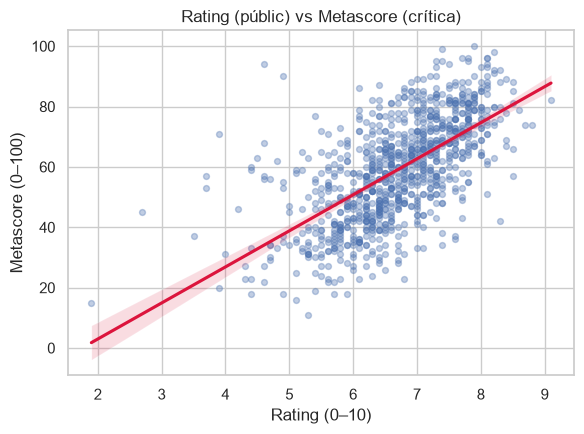

In [6]:
fig, ax = plt.subplots(figsize=(6, 4.5))
sns.regplot(data=sub, x="rating", y="metascore", scatter_kws={"alpha": 0.35, "s": 18},
            line_kws={"color": "crimson"}, ax=ax)
ax.set_title("Rating (públic) vs Metascore (crítica)")
ax.set_xlabel("Rating (0–10)"); ax.set_ylabel("Metascore (0–100)")
plt.tight_layout(); plt.show()

### Pel·lícules on públic i crítica discrepen més

In [7]:
sub["diferencia"] = sub["metascore"] - sub["rating"] * 10
top_dif = sub.reindex(sub["diferencia"].abs().sort_values(ascending=False).index).head(10)
top_dif[["title", "year", "rating", "metascore", "diferencia"]]

,title,year,rating,metascore,diferencia
633,Megan Is Missing,2011,4.6,94.0,48.0
73,Collateral Beauty,2016,6.8,23.0,-45.0
999,Nine Lives,2016,5.3,11.0,-42.0
604,The Rise of the Krays,2015,4.9,90.0,41.0
991,Taare Zameen Par,2007,8.3,42.0,-41.0
266,Dirty Grandpa,2016,5.9,18.0,-41.0
684,Seven Pounds,2008,7.6,36.0,-40.0
498,Law Abiding Citizen,2009,7.4,34.0,-40.0
835,The Loft,2014,6.3,24.0,-39.0
452,Pandorum,2009,6.7,28.0,-39.0


### Discrepància mitjana per gènere

,n,diferencia_mitjana
genres,,
Action,289,-11.85
Romance,131,-11.08
Family,50,-10.52
Fantasy,98,-10.41
Crime,141,-9.80
Adventure,249,-9.52
Mystery,99,-9.08
Comedy,268,-8.75
Sci-Fi,114,-8.43


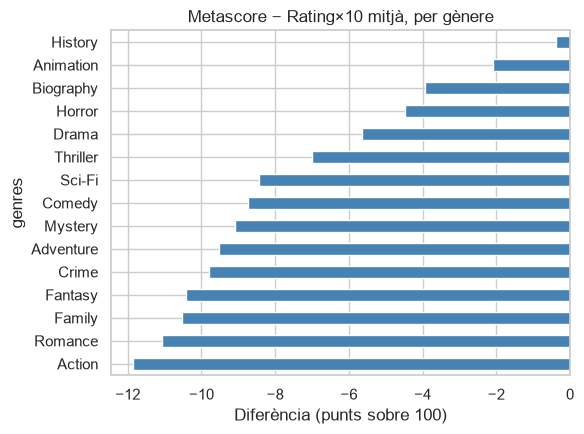

In [8]:
g = sub.explode("genres")
per_genere = (g.groupby("genres")
                .agg(n=("title", "count"), diferencia_mitjana=("diferencia", "mean"))
                .query("n >= 20")
                .sort_values("diferencia_mitjana"))
display(per_genere.round(2))

fig, ax = plt.subplots(figsize=(6, 4.5))
per_genere["diferencia_mitjana"].plot(kind="barh", color="steelblue", ax=ax)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_title("Metascore − Rating×10 mitjà, per gènere")
ax.set_xlabel("Diferència (punts sobre 100)")
plt.tight_layout(); plt.show()

## 3. Resultats

- Correlació de Pearson **0,63** i de Spearman **0,67** (n = 936): hi ha una relació positiva moderada-forta, però ni molt menys perfecta. Públic i crítica tendeixen a coincidir en termes generals, però no sempre.
- La diferència mitjana és d'uns **−8 punts** (desviació típica ≈13): de mitjana, el `Metascore` tendeix a ser una mica més baix que `Rating×10`, és a dir, la crítica sol ser més exigent que el públic.
- Els casos més extrems van en ambdues direccions: *Collateral Beauty* (6,8 de públic, 23 de crítica) i *Megan Is Missing* (4,9 de públic, 94 de crítica) mostren que la discrepància pot ser molt gran en casos puntuals.
- Per gènere, **Acció** i **Romance** són on la crítica és relativament més dura respecte al públic; **Història** i **Animació** són on més s'ajusten.


## 4. Interpretació i limitacions

✏️ **Omple-ho tu:** redacta 3–4 línies amb la teva pròpia interpretació (per exemple: per què la crítica podria ser més exigent en certs gèneres? Recorda que correlació no implica causalitat, i que `metascore` té 64 valors nuls que no hem considerat en aquest anàlisi).